# LIBRERIAS

In [1]:
import pybullet as p
import pybullet_data
import numpy as np
import matplotlib.pyplot as plt
import time
import ipywidgets as widgets
from IPython.display import display

#Conexión
if not p.isConnected():
    p.connect(p.GUI)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.8)

#Cargar el plano y robot
plane_id = p.loadURDF("plane.urdf")
robot_id = p.loadURDF("kuka_iiwa/model.urdf", useFixedBase = True)

#articulaciones
num_joints = p.getNumJoints(robot_id)
print(f"Robot cargado con {num_joints} articulaciones")

Robot cargado con 7 articulaciones


# MOVIMIENTO REUTILIZABLE

In [2]:
def mover_sinusoidal(pasos = 600, amplitud = 0.5, velocidad = 30, fps = 60):
    """Mover los 6 grados de libertad en una onda senoidal"""
    dt = 1.0 / fps
    for i in range(pasos):
        target_angles = [
            amplitud * np.sin(i / velocidad + j * 0.7) for j in range(6)
        ]
        p.setJointMotorControlArray(
            robot_id,
            jointIndices = range(6),
            controlMode = p.POSITION_CONTROL,
            targetPositions = target_angles,
            forces = [500] * 6,
            positionGains = [0.05] * 6,
        )
        p.stepSimulation()
        time.sleep(dt)
    print("Movimiento en onda senoidal terminado")

def mover_posicion (target_angles, pasos = 120):
    """Interpolar los ángulos que queremos suavemente"""
    actuales = [p.getJointState(robot_id, j)[0] for j in range(6)]
    for step in range(pasos):
        alpha = step / pasos
        interpolado = [
            (1 - alpha) * a + alpha * t 
            for a, t in zip(actuales, target_angles)
        ]
        p.setJointMotorControlArray(
            robot_id,
            jointindices = range(6),
            controlMode = p.POSITION_CONTROL,
            targetPositions = interpolado,
            forces = [500] * 6,
            positionGains = [0.05] * 6,
        )
        p.stepSimulation()

def reset():
    """Posición original"""
    for j in range(6):
        p.resetJointState(robot_id, j, 0.0)
    print('Robot reiniciado')

### GENERAR LOS BOTONES

In [ ]:
btn_iniciar = widgets.Button(
    description = "Iniciar movimiento",
    button_style = "success",
    layout = widgets.Layout(width = "200px"),
)

btn_detener = widgets.Button(
    description = "Reiniciar",
    button_style = "warning",
    layout = widgets.Layout(width = "200px"),
)
salida = widgets.Output()

def on_iniciar(b):
    with salida:
        salida.clear_output()
        print("Ejecutando movimiento en onda senoidal")
        mover_sinusoidal(pasos=600, amplitud=0.5, velocidad=30)

def on_detener(b):
    with salida:
        salida.clear_output()
        reset()

btn_iniciar.on_click(on_iniciar)
btn_detener.on_click(on_detener)

display(widgets.HBox([btn_iniciar, btn_detener]))
display(salida)

Output()

### FUNDAMENTOS DE CINEMATICA

Cuando hablamos de robots y su movimiento, tenemos que hablar de un tema aplicado de física y matemáticas. 

La cinemática directa es cuando hablamos de movimientos que conocemos los ángulos, pero queremos calcular la posición de cada eje.

La cinemática inversa, como su nombre lo dice, es cuando conocemos la posición final de los ejes, pero queremos calcular el ángulo de posición.

En esta parte, vamos a ver como funciona este concepto en dos dimensiones para verlo en el robot

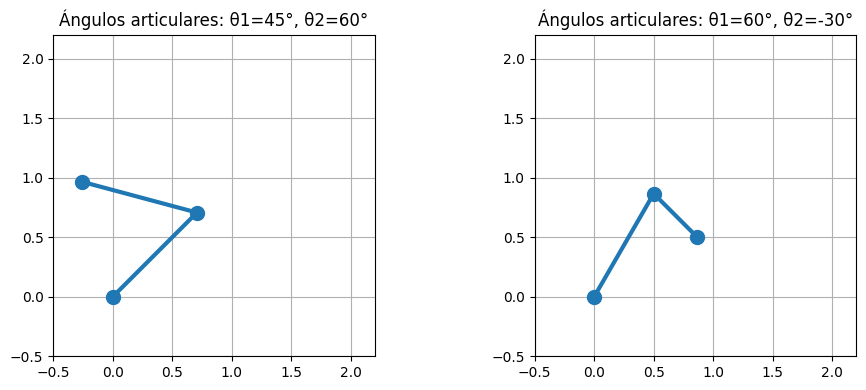

In [4]:
def forward_kinematic_2d (theta1, theta2, L1=1.0, L2=1.0):
    """Cinemática directa en dos dimensiones"""
    x1 = L1 * np.cos(theta1)
    y1 = L1 * np.sin(theta1)
    x2 = L2 * np.cos(theta1 + theta2)
    y2 = L2 * np.sin(theta1 + theta2)
    return x1, y1, x2, y2

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (t1, t2) in zip(axes, [(np.pi/4, np.pi/3), (np.pi/3, -np.pi/6)]):
    x1, y1, x2, y2 = forward_kinematic_2d(t1, t2)
    ax.plot([0, x1, x2], [0, y1, y2], 'o-', linewidth = 3, markersize=10)
    ax.set_xlim(-0.5, 2.2)
    ax.set_ylim(-0.5, 2.2)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_title(f"Ángulos articulares: θ1={np.degrees(t1):.0f}°, θ2={np.degrees(t2):.0f}°")
plt.tight_layout()
plt.show()

# RED NEURONAL PARA LA CINEMATICA INVERSA

Es más complicado calcular la cinemática inversa, ya que requiere un cálculo que no se ve en secundaria y que requiere un dominio muy alto de matemáticas. Por ello, aquí es donde vamos a utilizar un red neuronal para que aprenda a hacer estos cálculos e implementarlo en el modelo.

In [5]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split

"""Necesitamos general los datos de entrenamiento, para ello vamos a utilizar el modelo del robot"""
datos_X = [] #posición final de la garra
datos_Y = [] #ángulos de las 6 articulaciones

np.random.seed(42)
num_samples = 2000 # vamos a usar 2000 posiciones finales que queremos que el robot llegue

for _ in range(num_samples):
    #Va a tomar de forma aleatoria una posición objetivo dentro de las dimensiones del robot
    target_pos =[
        np.random.uniform(-0.3, 0.5),
        np.random.uniform(-0.4, 0.4),
        np.random.uniform(0.2, 0.8)
    ]
    joint_angles = p.calculateInverseKinematics(
        robot_id,
        endEffectorLinkIndex = 6, #La garra es la última articulación
        targetPosition = target_pos
    )
    datos_X.append(target_pos)
    datos_Y.append(joint_angles[:6])

data_X = np.array(datos_X)
data_y = np.array(datos_Y)

print(f"Se generaron {len(data_X)} conjunto de datos de entrenamiento")
print(f"Dimensiones de entrada: {data_X.shape} (x, y, z) de la garra")
print(f"Dimensiones de salida: {data_y.shape} (ángulos de las 6 articulaciones)")


Se generaron 2000 conjunto de datos de entrenamiento
Dimensiones de entrada: (2000, 3) (x, y, z) de la garra
Dimensiones de salida: (2000, 6) (ángulos de las 6 articulaciones)


## Entrenamiento

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    data_X, data_y, test_size=0.2, random_state=42
)

nn = MLPRegressor(
    hidden_layer_sizes=(100, 80 , 60), #3 capas
    activation= 'relu',
    solver = 'adam',
    max_iter=300,
    random_state=42,
    verbose = False
)

nn.fit(X_train, y_train)

train_score = nn.score(X_train, y_train)
test_score = nn.score(X_test, y_test)

print(f"R² en el conjunto de entrenamiento: {train_score:.4f}")
print(f"R² en el conjunto de pruebas: {test_score:.4f}")
print("\nCuanto mas cercano a 1 sea R², mejor ha aprendido la IA")

R² en el conjunto de entrenamiento: 0.9750
R² en el conjunto de pruebas: 0.9681

Cuanto mas cercano a 1 sea R², mejor ha aprendido la IA


# Movimiento controlado por la IA

Con lo aprendido por la IA, vamos a ver los movimientos predichos por la IA para que puedan hacer que el brazo alcance una posición objetivo

In [11]:
#Vamos a poner una posición a la que llegue
test_target = [0.3, 0.8, 0.5]
fps = 60
dt = 1/fps
print(f"Posición objetivo: x= {test_target[0]}, y= {test_target[1]}, z= {test_target[2]}")

#La IA va a predecir los ángulos de las articulaciones
predicted_angles = nn.predict([test_target])[0]
print(f"\nANGULOS ARTICULARES DE LA IA EN RADIANES: {predicted_angles}")
print(f"ANGULOS ARTICULARES PREDICHOS POR LA IA EN GRADOS: {np.degrees(predicted_angles)}")

#Movimientos
for i in range(300):
    p.setJointMotorControlArray(
                robot_id,
                jointIndices = range(6),
                controlMode = p.POSITION_CONTROL,
                targetPositions = predicted_angles,
                forces = [500] * 6,
                positionGains = [0.05] * 6,
    )
    p.stepSimulation()
    time.sleep(dt)

#Vamos a ver la posicion final de la garra
end_effector_pos = p.getLinkState(robot_id, 6)[0]
print(f"\nPosición alcanzada: x = {end_effector_pos[0]:.3f} y = {end_effector_pos[1]:.3f} z = {end_effector_pos[2]:.3f}")
print(f"Error: {np.linalg.norm(np.array(test_target) - np.array(end_effector_pos)):.4f} metros")

Posición objetivo: x= 0.3, y= 0.8, z= 0.5

ANGULOS ARTICULARES DE LA IA EN RADIANES: [ 0.92813611  0.4454904   0.26612906 -1.6909974  -0.10923238 -0.07010553]
ANGULOS ARTICULARES PREDICHOS POR LA IA EN GRADOS: [ 53.17828175  25.52471973  15.24807193 -96.88701409  -6.25855463
  -4.016751  ]

Posición alcanzada: x = 0.249 y = 0.552 z = 0.484
Error: 0.2533 metros


# EJEMPLO EN VIVO